# Answers Problem 2

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
plt.rcParams.update({'axes.grid':True,'grid.color':'black','grid.alpha':'0.25','grid.linestyle':'--'})
plt.rcParams.update({'font.size': 14})

from dstapi import DstApi

## 1. <a id='toc1_'></a>[List of categories](#toc0_)

List of categories:

In [ ]:
levels = DstApi('PRIS111').variable_levels('VAREGR',language='en' )

def verify(code,text):
    cond_1 = not (code[-2] == '0' and code[-1] == '0') # not an aggregate
    cond_2 = not ('/' in text.split(' ')[0] or '-' in text.split(' ')[0]) # not a range
    return cond_1 and cond_2

VAREGR_text = [row['text'] for _,row in levels.iterrows() if verify(row['id'], row['text'])]
VAREGR_codes = [row['id'] for _,row in levels.iterrows() if verify(row['id'], row['text'])]

print(f'{len(VAREGR_codes)} categories found.')
print(VAREGR_text[30])

## 2. <a id='toc2_'></a>[Distribution over time](#toc0_)

Download data:

In [ ]:
PRIS111 = DstApi('PRIS111')
params = PRIS111._define_base_params(language='en')
VAREGR = {'code': 'VAREGR','values': VAREGR_codes}
ENHED = {'code': 'ENHED','values': ['100']}
TID = {'code': 'Tid','values': ['*']}
params['variables'] = [VAREGR,ENHED,TID]
df_CPI_details = PRIS111.get_data(params)

Clean data:

In [ ]:
df_CPI_details['TID'] = pd.to_datetime(df_CPI_details['TID'], format='%YM%m')
df_CPI_details = df_CPI_details.drop(columns='ENHED')
df_CPI_details = df_CPI_details.rename(columns={'TID':'date','VAREGR':'item','INDHOLD':'CPI'})
df_CPI_details.CPI = df_CPI_details.CPI.replace('..','nan')
df_CPI_details.CPI = df_CPI_details.CPI.astype(float)
df_CPI_details = df_CPI_details.sort_values(['item','date'])
print(f'{df_CPI_details.CPI.isna().sum()} missing observations')
df_CPI_details.tail()

12-month inflation change:

In [5]:
df_CPI_details['inflation_12'] = df_CPI_details.groupby('item').CPI.transform(
    lambda x: x.pct_change(12, fill_method=None)*100)

In [6]:
df_CPI_details_agg = df_CPI_details.groupby('date').inflation_12.agg(
    p25 = lambda x: x.quantile(0.25),
    median = lambda x: x.quantile(0.5),
    p75 = lambda x: x.quantile(0.75),
    mean = 'mean'
    )
df_CPI_details_agg.tail()

,p25,median,p75,mean
date,,,,
2025-08-01,-0.492211,1.851852,3.865200,1.961282
2025-09-01,-1.154418,1.433121,4.061775,1.713398
2025-10-01,-0.385745,1.836158,4.677377,1.942890
2025-11-01,-0.770528,1.802403,4.428800,1.695703
2025-12-01,-1.228592,1.663340,4.082235,1.272859


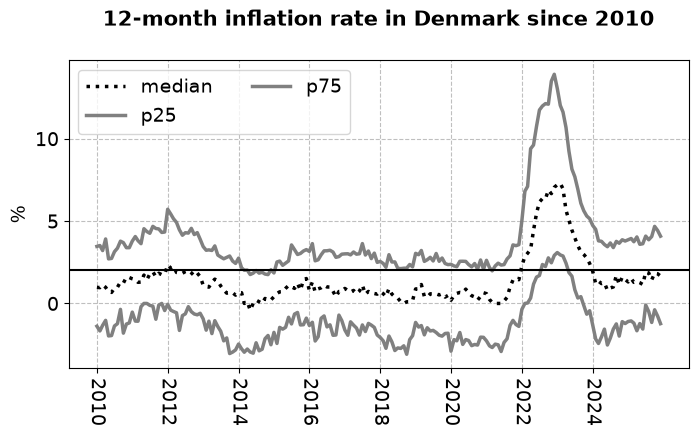

In [7]:
J = df_CPI_details_agg.index >= pd.to_datetime(2010,format='%Y')

fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.plot(df_CPI_details_agg[J].index,df_CPI_details_agg[J]['median'],label='median',color='black',lw=2.5,ls=':')
for name in ['p25','p75']:
    ax.plot(df_CPI_details_agg[J].index,df_CPI_details_agg[J][name],label=name,color='grey',lw=2.5,ls='-')

ax.axhline(2.0,color='black')

ax.set_xticks(df_CPI_details_agg[J].index[::24])
ax.set_xticklabels(df_CPI_details_agg[J].index[::24].year,rotation=270);

ax.set_ylabel('%')
ax.legend(ncol=2)
ax.set_title('12-month inflation rate in Denmark since 2010',
             pad=25.0,fontdict={'fontsize': 15, 'fontweight': 'bold'});

## 3. <a id='toc3_'></a>[Price changes since 2020](#toc0_)

### 3.1. <a id='toc3_1_'></a>[Data](#toc0_)

In [ ]:
dates = pd.to_datetime(['2020-08-01','2025-08-01'])

# pivot (rather than .agg(['first','last']), which silently skips missing values)
df_since_2020 = df_CPI_details[df_CPI_details.date.isin(dates)].pivot(index='item',columns='date',values='CPI')
df_since_2020.columns = ['first','last']

df_since_2020['change'] = (df_since_2020['last']/df_since_2020['first']-1)*100
df_since_2020 = df_since_2020.dropna(subset=['change'])
df_since_2020 = df_since_2020.sort_values('change',ascending=False)
df_since_2020.head().style.format('{:.1f}')


### 3.2. <a id='toc3_2_'></a>[Histogram](#toc0_)

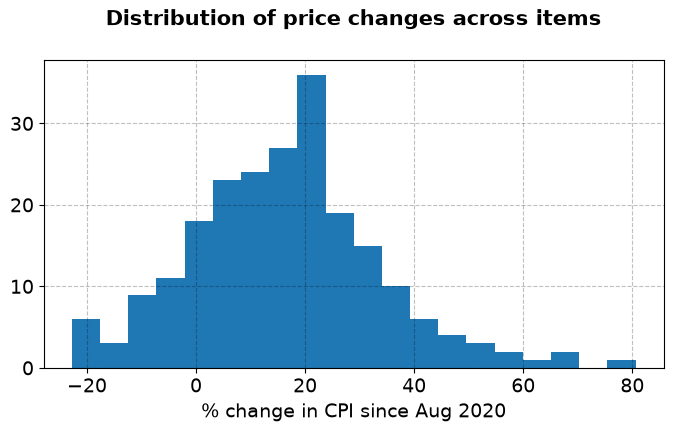

In [9]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)
ax.hist(df_since_2020.change.to_numpy(),bins=20)
ax.set_xlabel('% change in CPI since Aug 2020')
ax.set_title('Distribution of price changes across items',
                pad=25.0,fontdict={'fontsize': 15, 'fontweight': 'bold'});

## 4. <a id='toc4_'></a>[Top and bottom](#toc0_)

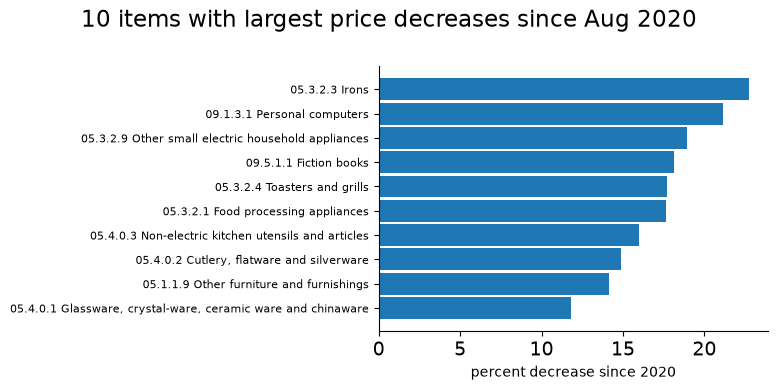

In [10]:
fig = plt.figure(figsize=(8,4))
ax = fig.add_subplot(1,1,1)

ax.barh(df_since_2020[-10:].index, -df_since_2020[-10:].change.values,height=0.9)
ax.set_xlabel('percent decrease since 2020',fontsize=10)

ax.set_yticks(range(len(df_since_2020[-10:].index)))
ax.set_yticklabels(df_since_2020[-10:].index,fontsize=8)

ax.grid(False)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

fig.suptitle('10 items with largest price decreases since Aug 2020')
fig.tight_layout()

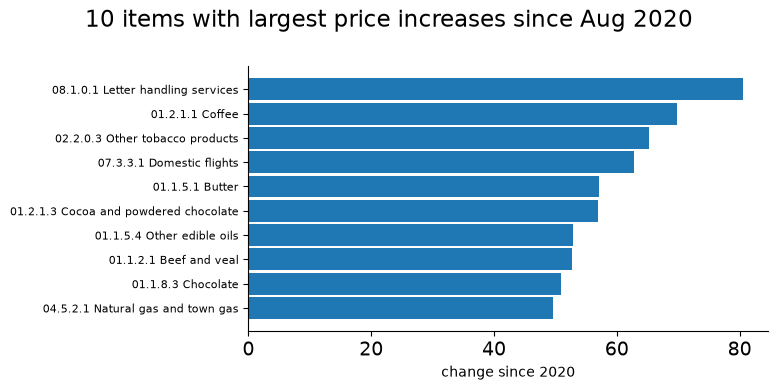

In [11]:
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(np.flip(df_since_2020[:10].index), np.flip(df_since_2020[:10].change.values),height=0.9)
ax.set_xlabel('change since 2020',fontsize=10)

ax.set_yticks(range(len(df_since_2020[:10].index)))
ax.set_yticklabels(np.flip(df_since_2020[:10].index),fontsize=8)

ax.grid(False)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)

fig.suptitle('10 items with largest price increases since Aug 2020')
fig.tight_layout()